# Pixelwise manipulation - Overlay

**Assumptions**
- We have either unlimited access to the target models api and / or a good enough understanding of it to construct a local surrogate model.
- We already know some images that reach a high score for certain classes.

**Goal**

Given any target image and target class we want to maximize the classes score on the given image.

**General idea**
1. Select target image and target class
2. Choose high-scoring known image according to target class
3. Overlay the target image with the low opacity known image to increase score on the target class

In [ ]:
%pip install numpy requests pillow matplotlib

In [38]:
import base64
import io
from typing import Dict, List

import numpy as np
import requests
from PIL import Image
from matplotlib import pyplot as plt

In [39]:
TARGET_SERVER_URL = "http://localhost:8000"
TARGET_EMOTION = "neutral"
TARGET_IMAGE = Image.open("../examples/happy.png")

# Hardcoded just for proof of concept
KNOWN_IMAGE = Image.open("../examples/sad.png")

In [40]:
session = requests.Session()


def parse_img_tobase64(image):
    buf = io.BytesIO()
    image.save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("utf-8")


def query_api(image) -> Dict:
    try:
        resp = session.post(
            TARGET_SERVER_URL + "/predict",
            json={"image": parse_img_tobase64(image), "classes": []},
            timeout=30,
        )
        resp.raise_for_status()
        return resp.json()["emotions"]
    except Exception as e:
        print(f"Request failed {e}")
        return {}


def plot_images_and_scores(images: List[Image.Image], target_emotion):
    _, axes = plt.subplots(1, len(images), figsize=(25, 5))

    for i, image in enumerate(images):
        axes[i].imshow(image)
        axes[i].set_title(query_api(image)[target_emotion])
        axes[i].axis("off")


def augment_image(target_image, target_emotion, strength):
    combined_image = target_image.copy()
    edited_known_image = KNOWN_IMAGE.copy()
    edited_known_image.putalpha(strength)
    combined_image.paste(im=edited_known_image, mask=edited_known_image)
    return combined_image


def pixelwise_manipulation_overlay_attack(target_image, target_emotion, strength=128):
    combined_image = augment_image(target_image, target_emotion, strength)

    plot_images_and_scores([target_image, KNOWN_IMAGE, combined_image], target_emotion)


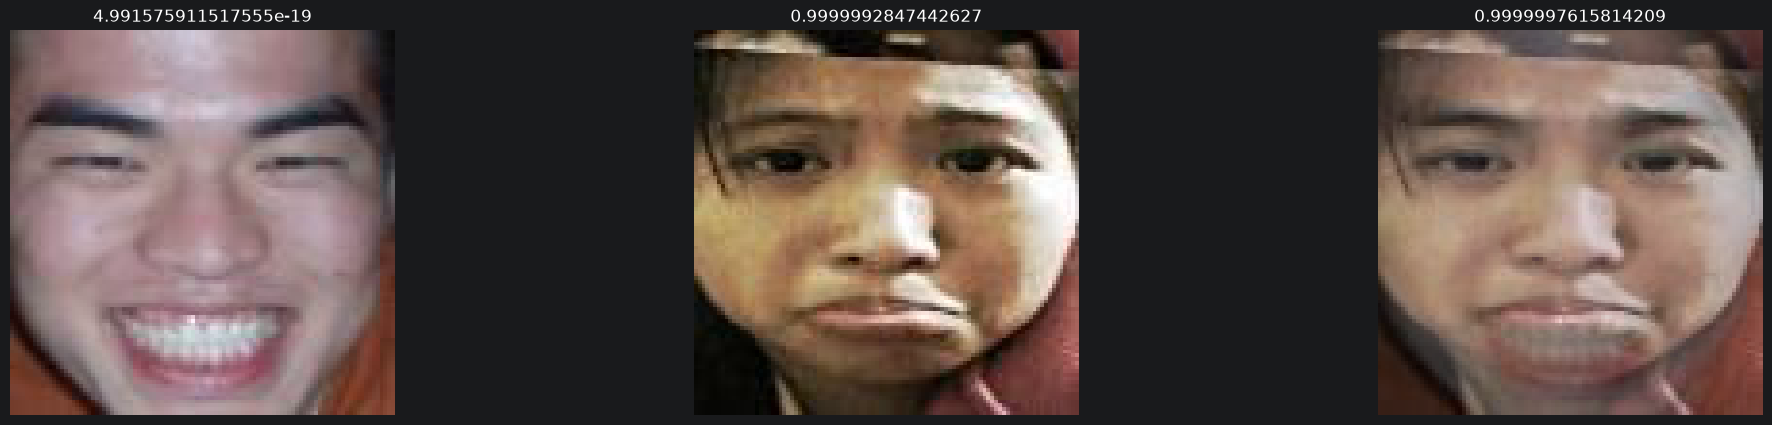

In [41]:
pixelwise_manipulation_overlay_attack(TARGET_IMAGE, TARGET_EMOTION, strength=145)

In [1]:
# Analysis in regard to strength

xs = np.ndarray((256 // 8) + 1)
ys = np.ndarray((256 // 8) + 1)
for i, s in enumerate(range(0, 256 + 1, 8)):
    augmented_image = augment_image(TARGET_IMAGE, TARGET_EMOTION, strength=s)
    xs[i] = s
    ys[i] = query_api(augmented_image)[TARGET_EMOTION]

plt.plot(xs, ys)

NameError: name 'np' is not defined